-Martina Yed-
Análisis y Procesamiento de Señales

TS0: Primeros pasos en la simulación


La función `mi_funcion_sen`que use en el codigo tiene estos parametros: 

* `vmax` (Amplitud máxima): Es el valor pico de la onda senoidal, medido en volts.
* `dc` (Valor medio):Es el nivel de tensión continua que se le suma a la señal. Determina si la oscilación está centrada en cero o si está desplazada hacia arriba o abajo en el eje vertical.
* `ff` (Frecuencia):Cantidad de ciclos por segundo que tiene la señal en Hz.
* `ph` (Fase):El corrimiento inicial de la señal (en radianes). Define desde qué punto del ciclo arranca la onda en el instante cero.
* `fs` (Frecuencia de muestreo):La velocidad con la que el conversor analógico-digital (ADC) toma las muestras de la señal (en Hz). 
* `nn` (Cantidad de muestras):El número total de puntos discretos que va a tener la señal digitalizada.


Al llamar a la función, esta nos devuelve dos vectores de dimensión Nx1:
* `tt`: El vector de tiempo (el eje X).
* `xx`: El vector con los valores de amplitud/voltaje para cada instante (el eje Y).

Empezamos analizando la frecuencia en 500Hz.

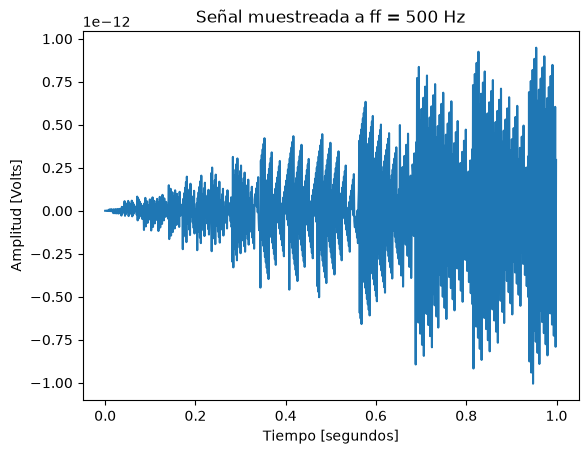

In [2]:
import matplotlib.pyplot as plt
import numpy as np

#%%  Definimos función 
def mi_funcion_sen(vmax=1, dc=0, ff=1, ph=0, nn=1000, fs=1000):
    n_vector = np.arange(nn)
    tt = n_vector / fs
    
    xx = vmax * np.sin(2 * np.pi * ff * tt + ph) + dc
    return(tt, xx)

#%% Parámetros generales 
N = 1000       # cantidad de muestras
vmax = 1.5     # amplitud
dc = 0         # nivel arbitrario (offset)
ff = 500        # frecuencia de la senoidal 
ph = 0         # fase
fs=1000
#%%  graficos
tt, xx = mi_funcion_sen(vmax=vmax, dc=dc, ff=ff, ph=ph, nn=N, fs=fs)
    
plt.figure()
plt.plot(tt, xx)
plt.title(f'Señal muestreada a ff = 500 Hz')
plt.xlabel('Tiempo [segundos]')
plt.ylabel('Amplitud [Volts]')
plt.show()

El código toma siempre N=1000 muestras. El tiempo total de la señal está dado por la fórmula T=N/fs. Por lo tanto, la cantidad de ciclos que se van a ver en la pantalla son. Ciclos= f x N/fs. 
Tomando que ahora estamos con f=500 Hz, N=1000 Y fs=1000 Hz, serían 500 ciclos exactos.
Relacionándolo con la teoría de muestreo, la frecuencia en tiempo discreto equivalente se define mediante la relación w=2f/fs. Al reemplazar esta ecuación con estos parámetros, obtenemos una frecuencia discreta de w0=pi. La secuencia de la señal se convierte en cos(pin), esto equivale matemáticamente a la secuencia alternante (-1)n. Para entender la diferencia entre estos dos conceptos, me resulta útil pensarlo de la siguiente manera: los 500 ciclos son la cantidad de repeticiones totales de la señal que entran en nuestra ventana de tiempo total. Por otro lado, las 2 muestras representan la cantidad de puntos individuales que el conversor analógico-digital (ADC) logra capturar para reconstruir uno solo de esos ciclos. 


Seguimos analizando la frecuencia en 999Hz.

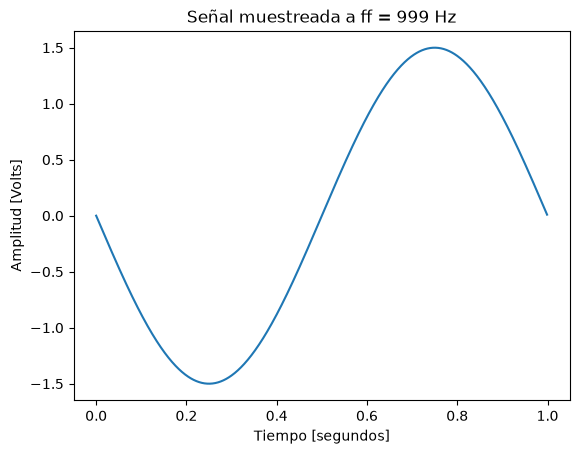

In [1]:
import matplotlib.pyplot as plt
import numpy as np

#%%  Definimos función 
def mi_funcion_sen(vmax=1, dc=0, ff=1, ph=0, nn=1000, fs=1000):
    n_vector = np.arange(nn)
    tt = n_vector / fs
    
    xx = vmax * np.sin(2 * np.pi * ff * tt + ph) + dc
    return(tt, xx)

#%% Parámetros generales 
N = 1000       # cantidad de muestras
vmax = 1.5     # amplitud
dc = 0         # nivel arbitrario (offset)
ff = 999         # frecuencia de la senoidal 
ph = 0         # fase
fs=1000
#%%  graficos
tt, xx = mi_funcion_sen(vmax=vmax, dc=dc, ff=ff, ph=ph, nn=N, fs=fs)
    
plt.figure()
plt.plot(tt, xx)
plt.title(f'Señal muestreada a ff = 999 Hz')
plt.xlabel('Tiempo [segundos]')
plt.ylabel('Amplitud [Volts]')
plt.show()

Para entender este fenómeno extremo a 999 Hz, resulta útil pensar en la escala de observación. En nuestra ventana de tiempo total, la señal analógica real completa 999 ciclos. Sin embargo, como el ADC captura 1000 puntos en ese mismo lapso, dispone de apenas 1001(aprox) muestras para caracterizar cada uno de esos ciclos individuales. Al tomar prácticamente una sola captura por oscilación, el conversor carece de la resolución necesaria para registrar el detalle de las subidas y bajadas rápidas. En consecuencia, al unir los puntos obtenidos, se reconstruye visualmente un único ciclo aparente (un alias de 1 Hz) que ocupa toda la pantalla.

Para visualizar este fenómeno, me sirvio mucho imaginarmelo asi. Marcamos la rueda de un auto. Si la rueda da 999 vueltas por segundo y la cámara saca 1000 fotos por segundo (nuestra frecuencia de muestreo), en cada captura la rueda casi completó un giro, quedando apenas retrasada. Al reproducir el video, la ilusión óptica nos hace creer que gira lentamente hacia atrás a 1 vuelta por segundo (1 Hz). A nuestro conversor (ADC) le pasa exactamente lo mismo: al tomar prácticamente un solo punto por ciclo, pierde el movimiento rápido real y termina uniendo las muestras para dibujar una onda aparente mucho más lenta.

Frecuencia 1001Hz.

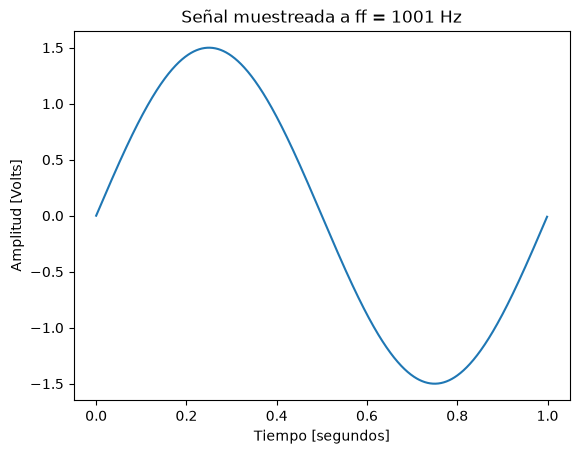

In [1]:
import matplotlib.pyplot as plt
import numpy as np

#%%  Definimos función 
def mi_funcion_sen(vmax=1, dc=0, ff=1, ph=0, nn=1000, fs=1000):
    n_vector = np.arange(nn)
    tt = n_vector / fs
    
    xx = vmax * np.sin(2 * np.pi * ff * tt + ph) + dc
    return(tt, xx)

#%% Parámetros generales 
N = 1000       # cantidad de muestras
vmax = 1.5     # amplitud
dc = 0         # nivel arbitrario (offset)
ff = 1001         # frecuencia de la senoidal 
ph = 0         # fase
fs=1000
#%%  graficos
tt, xx = mi_funcion_sen(vmax=vmax, dc=dc, ff=ff, ph=ph, nn=N, fs=fs)
    
plt.figure()
plt.plot(tt, xx)
plt.title(f'Señal muestreada a ff = 1001 Hz')
plt.xlabel('Tiempo [segundos]')
plt.ylabel('Amplitud [Volts]')
plt.show()

Al configurar la frecuencia de la señal en 1001 Hz (fs=1000), la matemática nos da una frecuencia discreta de w= 2.002\pi. Como las secuencias discretas son periódicas cada 2\pi, esto equivale a restarle una vuelta entera, dejándonos con w = 0.002\pi. Esto es exactamente la frecuencia discreta de una señal de 1 Hz.
Pensándolo en el ejemplo de la rueda que venimso usando, la rueda ahora da 1001 vueltas por segundo, pero la cámara sigue sacando 1000 fotos por segundo. Entre captura y captura, la rueda logra dar una vuelta completa y avanza un poquitito más. La ilusión óptica ahora nos hace creer que gira lentamente hacia adelante, dando 1 vuelta por segundo (1 Hz). Como la forma de la onda del coseno es perfectamente simétrica (es una función par), este ciclo falso de 1 Hz hacia adelante se ve exactamente igual en la pantalla que el ciclo hacia atrás que vimos con los 999 Hz.

Por ultimo la frecuencia 2001Hz

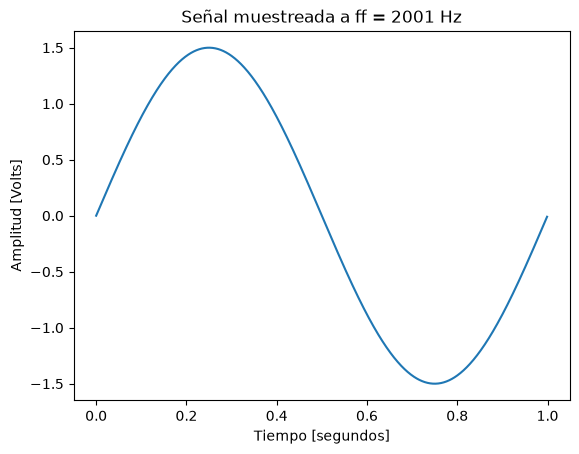

In [2]:
import matplotlib.pyplot as plt
import numpy as np

#%%  Definimos función 
def mi_funcion_sen(vmax=1, dc=0, ff=1, ph=0, nn=1000, fs=1000):
    n_vector = np.arange(nn)
    tt = n_vector / fs
    
    xx = vmax * np.sin(2 * np.pi * ff * tt + ph) + dc
    return(tt, xx)

#%% Parámetros generales 
N = 1000       # cantidad de muestras
vmax = 1.5     # amplitud
dc = 0         # nivel arbitrario (offset)
ff = 2001         # frecuencia de la senoidal 
ph = 0         # fase
fs=1000
#%%  graficos
tt, xx = mi_funcion_sen(vmax=vmax, dc=dc, ff=ff, ph=ph, nn=N, fs=fs)
    
plt.figure()
plt.plot(tt, xx)
plt.title(f'Señal muestreada a ff = 2001 Hz')
plt.xlabel('Tiempo [segundos]')
plt.ylabel('Amplitud [Volts]')
plt.show()

Al configurar la frecuencia de la señal en 2001 Hz (con fs=1000Hz), la matemática nos da una frecuencia discreta de w=4.002pi. Como las secuencias discretas son periódicas cada 2pi, esto equivale a restarle dos vueltas enteras (4pi), dejándonos con w=0.002pi. Esto vuelve a resultar en la frecuencia discreta equivalente de una señal de 1 Hz.
Volviendo al ejemplo, nuestra rueda ahora da 2001 vueltas por segundo, pero la cámara sigue sacando 1000 fotos por segundo. Entre captura y captura, la rueda no solo da una vuelta entera, sino dos vueltas completas y avanza un poquitito más. Al ser un giro tan veloz frente a la baja tasa de muestreo, el conversor digital sufre una distorsión total del movimiento real y, al unir los puntos, la ilusión óptica hace que parezca que gira lentamente hacia adelante, completando un único ciclo aparente de 1 Hz. Debido a las propiedades de simetría de la función coseno, este fenómeno de aliasing se dibuja exactamente igual en la pantalla, reflejando cómo las frecuencias superiores al límite de Nyquist colapsan sobre el rango principal

CONCLUSION

El análisis de las distintas frecuencias nos permitió observar dos fenómenos críticos que ocurren dentro del conversor analógico-digital (ADC):


El límite de Nyquist ff=500Hz: Al igualar la frecuencia de la señal a exactamente la mitad de la frecuencia de muestreo fs=1000Hz, operamos en la frontera de las capacidades del sistema. Utilizando la relación de la frecuencia equivalente en tiempo discreto, comprobamos que el sistema colapsa a la frecuencia discreta límite de pi.

Aliasing y periodicidad espectral (ff= 999Hz, 1001Hz y 2001Hz):Como bien explica la bibliografía oficial, en Holton cap3 dice que las secuencias exponenciales complejas y la Transformada de Fourier en Tiempo Discreto (DTFT) son periódicas con un período de $2\pi$. Esto significa que el espectro se repite infinitamente en forma de ciclos. Por lo tanto, si una frecuencia se nos va y cae fuera del rango principal de análisis (-pi <= w < pi), la teoría nos permite encontrar su equivalente simplemente sumando o restando el múltiplo de 2pi que corresponda. 


Físicamente, yo logre interpretar este fenómeno de aliasing a través de la analogía de una cámara de fotos capturando una rueda en movimiento. Cuando la señal física oscila a velocidades mucho mayores que la tasa de captura del ADC, el hardware simplemente carece de la resolución temporal necesaria para 'ver' el trayecto real de la onda entre muestra y muestra. Al unir los puntos, el conversor dibuja inevitablemente un ciclo falso que engaña a la vista.